In [10]:
#Cargamos librerias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.special as special
from scipy.optimize import curve_fit
import seaborn as sns
from sklearn.metrics import r2_score

In [11]:

#Cargar archivo xlsx
df = pd.read_excel('Datos_Complementarios_CLV.xlsx', sheet_name='Histórico_Entradas_SAlidas')
df.head(5)

#Conocemos el df (dimensiones y asi)
print("Dimensiones de la base:", df.shape)
print("Columnas disponibles:", df.columns.tolist())
display(df.head())

Dimensiones de la base: (55180, 7)
Columnas disponibles: ['ANO', 'MES', 'SKU', 'NOMBRE', 'MARCA', 'SALIDAS', 'ALMACEN']


,ANO,MES,SKU,NOMBRE,MARCA,SALIDAS,ALMACEN
0,2026,10,MFTS502L1.5,MFT S50 2L1.5,VITA,2,Almacén general
1,2026,10,AKZLCSTANDKIT,AKZENT LC STANDARD KIT,VITA,1,Almacén general
2,2026,10,LIN23LINF3M2,LINGOFORM 23L INFERIOR 3M2,VITA,1,Almacén general
3,2026,10,LIN23LSUP3M2,LINGOFORM2 23LSUPERIOR 3M2,VITA,1,Almacén general
4,2026,10,PANEXCL39A3,PAN EXCELL L39 A3,VITA,1,Almacén general


In [12]:
# Devuelve directamente el número más grande de la columna SALIDAS
valor_maximo = df["SALIDAS"].max()
print(valor_maximo)


1663


In [13]:
# Asegurar que SALIDAS sea numérica
df["SALIDAS"] = pd.to_numeric(df["SALIDAS"], errors="coerce")

# Estadísticas generales
print("Máximo:", df["SALIDAS"].max())
print("Mínimo:", df["SALIDAS"].min())
print("Mediana:", df["SALIDAS"].median())

# Mostrar los 20 movimientos con mayores salidas
mayores_salidas = df.sort_values(
    by="SALIDAS",
    ascending=False
).head(20)

display(
    mayores_salidas[
        ["ANO", "MES", "SKU", "NOMBRE", "MARCA", "SALIDAS", "ALMACEN"]
    ]
)

# Identificar el registro con el valor máximo
indice_max = df["SALIDAS"].idxmax()

display(df.loc[indice_max])

Máximo: 1663
Mínimo: 1
Mediana: 3.0


,ANO,MES,SKU,NOMBRE,MARCA,SALIDAS,ALMACEN
52092,2021,7,259300,S&S SPEEDVEST 20 X 160G + 750ML,Schef,1663,Almacén general
49730,2021,7,COL3DM,COLORIMETRO 3D MASTER,VITA,913,Almacén general
49189,2021,7,MFTO402M2,MFT O40 2M2,VITA,619,Almacén general
51432,2021,7,MFTT432M2,MFT T43 2M2,VITA,581,Almacén general
51462,2021,7,MFTR422M2,MFT R42 2M2,VITA,474,Almacén general
49167,2021,7,MFTO492M2,MFT O49 2M2,VITA,469,Almacén general
49171,2021,7,MFTO442M2,MFT O44 2M2,VITA,462,Almacén general
28787,2023,9,MFTPU332M2,MFT PU33 2M2,VITA,426,Almacén general
51485,2021,7,MFTR473M2,MFT R47 3M2,VITA,418,Almacén general
49170,2021,7,MFTO493M2,MFT O49 3M2,VITA,404,Almacén general


ANO                                   2021
MES                                      7
SKU                                 259300
NOMBRE     S&S SPEEDVEST 20 X 160G + 750ML
MARCA                                Schef
SALIDAS                               1663
ALMACEN                    Almacén general
Name: 52092, dtype: object

In [19]:
salidas_mensuales = (
    df.groupby(["ANO", "MES"])["SALIDAS"]
    .sum()
    .reset_index()
    .sort_values("SALIDAS", ascending=False)
)

display(salidas_mensuales.head(10))

,ANO,MES,SALIDAS
5,2021,7,74539
58,2025,12,15990
62,2026,4,15757
59,2026,1,14600
55,2025,9,12500
50,2025,4,11615
39,2024,5,10292
36,2024,2,9773
47,2025,1,9543
18,2022,8,9134


>> **MINI SIDENOTE** Durante la revisión de los datos se identificó un valor atípico de 74,539 unidades en julio de 2021. Sin embargo, al investigar su origen, se comprobó que este valor corresponde a la suma de múltiples registros agrupados por año y mes, y no a una observación individual. Por ello, no se considera justificable imputarlo ni modificarlo sin evidencia de errores en los registros originales. Se conserva para mantener la integridad de la información histórica.

>>Para futuros analisis se debe eliminar o imputar con la media para evitar la dispersion de datos en el analisis o en su defecto hacer ambas versiones y dejarlo a consideracion del **socio formador** ya que es un dato historico/ relevante para el negocio

,ANO,MES,SALIDAS,tiempo
0,2019,1,286,0
1,2021,3,3373,1
2,2021,4,5195,2
3,2021,5,4758,3
4,2021,6,5142,4


Número de observaciones mensuales: 69


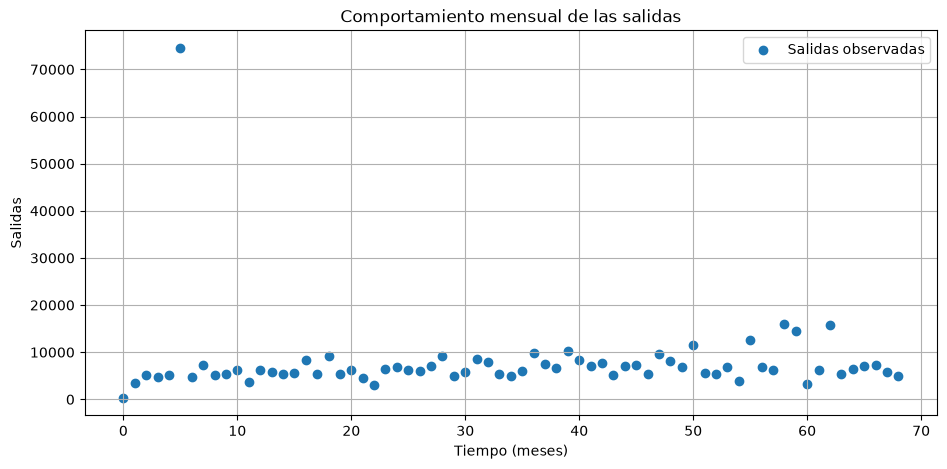

In [20]:
##PREPARAMOS LAS VARIABLES## Usaremos salidas x año y mes

# Verificar que existan las columnas necesarias
columnas_necesarias = ["ANO", "MES", "SALIDAS"]
faltantes = [col for col in columnas_necesarias if col not in df.columns]

if faltantes:
    raise ValueError(f"Faltan estas columnas en la hoja: {faltantes}")

# Convertir a formato numérico y excluir registros incompletos
datos = df[columnas_necesarias].copy()
for col in columnas_necesarias:
    datos[col] = pd.to_numeric(datos[col], errors="coerce")

datos = datos.dropna(subset=columnas_necesarias)

# Agrupar salidas por año y mes
ventas = (
    datos.groupby(["ANO", "MES"], as_index=False)["SALIDAS"]
    .sum()
    .sort_values(["ANO", "MES"])
    .reset_index(drop=True)
)

# Variable independiente: tiempo (meses)
ventas["tiempo"] = np.arange(len(ventas))

display(ventas.head())
print("Número de observaciones mensuales:", len(ventas))

plt.figure(figsize=(11, 5))
plt.scatter(ventas["tiempo"], ventas["SALIDAS"], label="Salidas observadas")
plt.xlabel("Tiempo (meses)")
plt.ylabel("Salidas")
plt.title("Comportamiento mensual de las salidas")
plt.grid(True)
plt.legend()
plt.show()

#Definición de los modelos no lineales

**Modelo 1. Cuadrático**

\[
y = ax^2 + bx + c
\]
>> Porque representa tendencias curvas, aceleraciones, desaceleraciones y cambios de dirección.

**Modelo 2. Exponencial**

\[
y = ae^{-bx} + c
\]
>>	Permite representar crecimiento o decrecimiento a tasas proporcionales, así como tendencias que se aproximan a un valor límite.

En ambos modelos la intención es comparar dos formas distintas de representar el comportamiento de las salidas a través del tiempo, utilizando `x` para el tiempo en meses y `y` para las salidas mensuales.

In [15]:
# Preparar arreglos numéricos
x = ventas["tiempo"].to_numpy(dtype=float)
y = ventas["SALIDAS"].to_numpy(dtype=float)

# Funciones de ajuste
def modelo_cuadratico(x, a, b, c):
    return a * x**2 + b * x + c

def modelo_exponencial(x, a, b, c):
    return a * np.exp(-b * x) + c

modelos = {
    "Cuadrático": modelo_cuadratico,
    "Exponencial": modelo_exponencial
}

print("Variables listas:", len(x))

Variables listas: 69


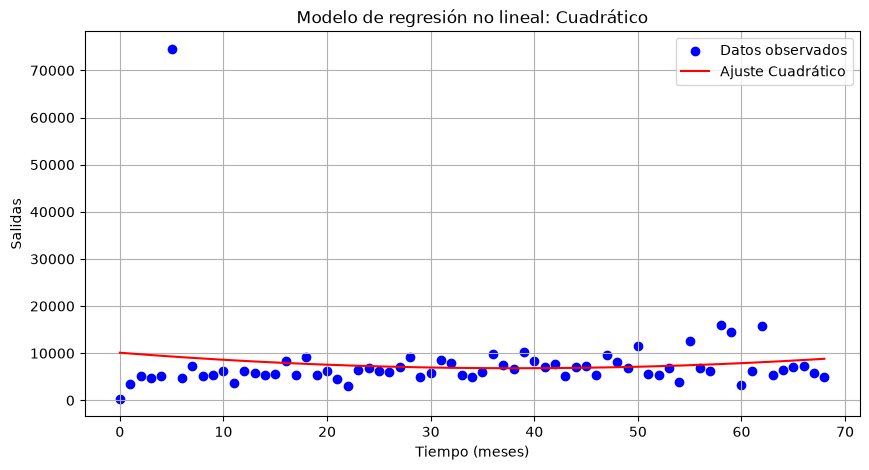

Modelo Cuadrático
Parámetros estimados: [ 2.25578987e+00 -1.72303725e+02  1.01041413e+04]
R² = 0.0107
R = 0.1037
---------------------------------------------


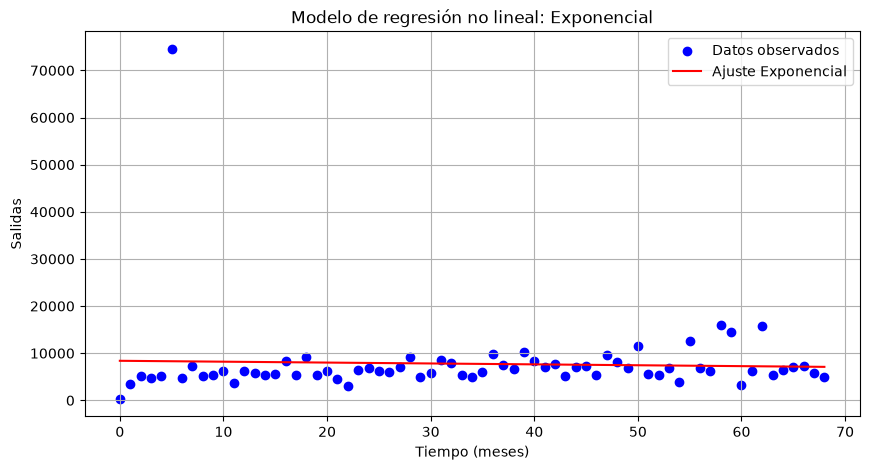

Modelo Exponencial
Parámetros estimados: [-2.15597387e+06 -8.76551138e-06  2.16436488e+06]
R² = 0.0019
R = 0.0441
---------------------------------------------


In [16]:
##GRAFICACION##

#Hacemos las listas en donde se van a ir guardando nuestras variables
resultados = []
ajustes = {}

for nombre, funcion in modelos.items():
    try:
        # Valores iniciales para facilitar la convergencia
        if nombre == "Cuadrático":
            p0 = [0.0, 0.0, float(np.mean(y))]
        else:
            p0 = [float(y.max() - y.min()), 0.01, float(y.min())]

        parametros, covarianza = curve_fit(
            funcion,
            x,
            y,
            p0=p0,
            maxfev=50000
        )

        predicciones = funcion(x, *parametros)
        r2 = r2_score(y, predicciones)

        # Procedimiento de correlación utilizado en el notebook de clase
        r_clase = np.sqrt(abs(r2))

        ajustes[nombre] = {
            "funcion": funcion,
            "parametros": parametros,
            "predicciones": predicciones
        }

        resultados.append({
            "Modelo": nombre,
            "R² (determinación)": r2,
            "R (procedimiento de clase)": r_clase
        })

        # Gráfica!
        x_suave = np.linspace(x.min(), x.max(), 300)
        y_suave = funcion(x_suave, *parametros)

        plt.figure(figsize=(10, 5))
        plt.scatter(x, y, color="blue", label="Datos observados")
        plt.plot(x_suave, y_suave, color="red", label=f"Ajuste {nombre}")
        plt.xlabel("Tiempo (meses)")
        plt.ylabel("Salidas")
        plt.title(f"Modelo de regresión no lineal: {nombre}")
        plt.grid(True)
        plt.legend()
        plt.show()

        print(f"Modelo {nombre}")
        print("Parámetros estimados:", parametros)
        print(f"R² = {r2:.4f}")
        print(f"R = {r_clase:.4f}")
        print("-" * 45)

    except (RuntimeError, ValueError, FloatingPointError) as error:
        print(f"No fue posible ajustar el modelo {nombre}: {error}")

In [17]:
#HACEMOS LA TABLA COMPARATIVA DE LOS RESULTADOS
tabla_resultados = pd.DataFrame(resultados)
display(tabla_resultados.round(4))

# Identificar el modelo con mayor R²
mejor = tabla_resultados.loc[tabla_resultados["R² (determinación)"].idxmax()]
print(
    f"El mayor R² corresponde al modelo {mejor['Modelo']}, "
    f"con un valor de {mejor['R² (determinación)']:.4f}."
)

,Modelo,R² (determinación),R (procedimiento de clase)
0,Cuadrático,0.0107,0.1037
1,Exponencial,0.0019,0.0441


El mayor R² corresponde al modelo Cuadrático, con un valor de 0.0107.
